<a href="https://colab.research.google.com/github/ZiyuCao421/26-CP5046-SIN-CAM-TR3-ICT-Project-1-Analysis-and-Design/blob/main/V3/notebooks/05_combined_feature_set_champion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 5 — Combined Feature-Set Champion Evaluation

This notebook evaluates **Shah's three exported candidate sets** and **Ziyu's V3 FS1–FS3** under one data contract: the same complete-case cohort, one fixed stratified split, unchanged models, and Macro F1 as the primary metric.

It produces a **provisional held-out champion**, not a deployment or new-user generalisation claim. Shah's feature lists must be exported from his executed Colab notebook and pasted into the configuration cell; never infer them from a chart.

## Run order

1. Mount Google Drive.
2. Set the four paths in the next cell.
3. Paste Shah's final feature names into `SHAH_FEATURE_SETS`.
4. Run all remaining cells from top to bottom.

The column spelling must exactly match the merged course CSV files. Empty Shah lists are deliberately rejected: a cross-developer champion cannot be selected if Shah's sets are absent.

In [1]:
# Optional in Google Colab: run once per fresh runtime.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ======================== CONFIGURATION — EDIT THIS CELL ========================
from pathlib import Path

# Folder containing the original UserN_*.csv course files.
RAW_DATA_DIR = '/content/drive/MyDrive/ICT Project MOUSE/Project/mouseDyanamicsData'
FILE_PATTERN = '**/*.csv'

# Existing V3 aggregate-output folders (optional continuity check).
ZIYU_STAGE1_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/results/single_feature'
ZIYU_STAGE3_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/results/feature_sets'
OUTPUT_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/results/combined_champion'
# Keep False if your Drive stores Stage-1/3 outputs in different folders.
# The actual comparison needs RAW_DATA_DIR plus the declared feature lists.
VALIDATE_EXISTING_V3_OUTPUTS = False

RANDOM_STATE = 42
TEST_SIZE = 0.20
# All six declared sets are now present. Keep False for the final combined comparison.
ALLOW_PARTIAL_COMPARISON = False

# Shah lists transcribed from his completed Colab outputs (Cells 42, 46, 50).
# RF is transparently a displayed Top-10 proxy: its complete SelectFromModel list had 19 columns.
SHAH_FEATURE_SETS = {
    'SHAH_anova_top10': ['min_a', 'min_j', 'avg_av', 'J0', 'min_av', 'min_am', 'avg_am', 'A2', 'max_am', 'AM2'],
    'SHAH_random_forest_top10_proxy': ['max_d', 'avg_j', 'min_a', 'avg_d', 'min_j', 'max_j', 'J0', 'avg_a', 'J2', 'A1'],
    'SHAH_lasso_top10': ['min_a', 'avg_d', 'min_d', 'd0', 'min_tv', 'min_j', 'HV0', 'max_tv', 'TV2', 'TV1'],
}
FEATURE_SET_PROVENANCE = {
    'SHAH_anova_top10': 'Shah Colab Cell 42: SelectKBest(f_classif, k=10), displayed top-10 table.',
    'SHAH_random_forest_top10_proxy': 'Shah Colab Cell 46: displayed RF importance top-10. It is a proxy, not the full 19-column SelectFromModel output.',
    'SHAH_lasso_top10': 'Shah Colab Cell 50: L1 Logistic Regression displayed top-10; output confirms 10 columns.',
    'ZIYU_FS1_consensus_compact': 'Ziyu V3 Stage 3 documented definition.',
    'ZIYU_FS2_svc_diverse': 'Ziyu V3 Stage 3 documented definition.',
    'ZIYU_FS3_random_forest_diverse': 'Ziyu V3 Stage 3 documented definition.',
}

ZIYU_FEATURE_SETS = {
    'ZIYU_FS1_consensus_compact': ['max_y', 'min_t', 'min_x', 'VV2', 'VV0', 'min_hv'],
    'ZIYU_FS2_svc_diverse': ['avg_t', 'max_y', 'min_x', 'VV2', 'min_hv', 'VV0'],
    'ZIYU_FS3_random_forest_diverse': ['min_y', 'VV0', 'VV2', 'min_hv', 'min_t', 'min_x'],
}
# ================================================================================

In [3]:
import hashlib, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style='whitegrid', context='notebook')
raw_dir = Path(RAW_DATA_DIR)
stage1_dir = Path(ZIYU_STAGE1_DIR)
stage3_dir = Path(ZIYU_STAGE3_DIR)
out_dir = Path(OUTPUT_DIR)
fig_dir = out_dir / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)

def require(condition, message):
    if not condition:
        raise RuntimeError(message)

def sha256_text(value):
    return hashlib.sha256(value.encode('utf-8')).hexdigest()

def find_raw_data_dir(configured_path):
    # First try the configured path and known project locations.
    candidates = [Path(configured_path),
                  Path('/content/drive/MyDrive/ICT Project MOUSE/Project/mouseDyanamicsData'),
                  Path('/content/drive/MyDrive/CP5046_Mouse_Dynamics')]
    for candidate in candidates:
        if candidate.is_dir() and any(candidate.glob('User*_Calib_3MouseMovement_MCQ_Segment.csv')):
            return candidate
    # Last resort: search MyDrive for the known course-file naming pattern.
    drive_root = Path('/content/drive/MyDrive')
    if drive_root.is_dir():
        match = next(drive_root.rglob('User*_Calib_3MouseMovement_MCQ_Segment.csv'), None)
        if match is not None:
            return match.parent
    return None

found_raw_dir = find_raw_data_dir(RAW_DATA_DIR)
require(found_raw_dir is not None, 'Could not find a folder containing User*_Calib_3MouseMovement_MCQ_Segment.csv. Mount Drive, then set RAW_DATA_DIR to that folder.')
raw_dir = found_raw_dir
print(f'RAW_DATA_DIR selected automatically: {raw_dir}')
if VALIDATE_EXISTING_V3_OUTPUTS:
    require((stage1_dir / 'feature_inventory.csv').is_file(), 'Missing Stage-1 feature_inventory.csv. Correct ZIYU_STAGE1_DIR.')
    require((stage3_dir / 'feature_set_definitions.json').is_file(), 'Missing Stage-3 feature_set_definitions.json. Correct ZIYU_STAGE3_DIR.')
else:
    print('V3 aggregate-file validation skipped; static FS1–FS3 definitions remain recorded below.')
empty_shah_sets = [name for name, values in SHAH_FEATURE_SETS.items() if not values]
if empty_shah_sets and not ALLOW_PARTIAL_COMPARISON:
    raise RuntimeError('Paste all three exported Shah feature lists before running the final combined comparison: ' + ', '.join(empty_shah_sets))
active_shah_sets = {name: values for name, values in SHAH_FEATURE_SETS.items() if values}
feature_sets = {**active_shah_sets, **ZIYU_FEATURE_SETS}
combined_comparison_complete = not empty_shah_sets
if combined_comparison_complete:
    comparison_scope = 'complete: Shah ANOVA, Random Forest and Lasso sets plus Ziyu FS1–FS3'
else:
    comparison_scope = 'partial: only declared non-empty sets; not a Shah-versus-Ziyu champion decision'
    print('WARNING — partial comparison only. Shah lists omitted:', ', '.join(empty_shah_sets))
print(f'Candidate sets evaluated: {len(feature_sets)}')
for name, columns in feature_sets.items():
    print(f'  {name}: {len(columns)} features')

RAW_DATA_DIR selected automatically: /content/drive/MyDrive/CP5046_Mouse_Dynamics
V3 aggregate-file validation skipped; static FS1–FS3 definitions remain recorded below.
Candidate sets evaluated: 6
  SHAH_anova_top10: 10 features
  SHAH_random_forest_top10_proxy: 10 features
  SHAH_lasso_top10: 10 features
  ZIYU_FS1_consensus_compact: 6 features
  ZIYU_FS2_svc_diverse: 6 features
  ZIYU_FS3_random_forest_diverse: 6 features


In [4]:
# Read every source file and create/standardise the multi-class user label.
course_file_pattern = re.compile(r'^user[ _-]?\d+.*mousemovement.*segment\.csv$', flags=re.I)
all_csv_files = sorted(p for p in raw_dir.glob(FILE_PATTERN) if p.is_file())
raw_files = [path for path in all_csv_files if course_file_pattern.match(path.name)]
ignored_csv_files = [path for path in all_csv_files if path not in raw_files]
require(raw_files, f'No course CSV files matched the UserN_*MouseMovement*Segment.csv pattern in {raw_dir}')
print(f'Course CSV files selected: {len(raw_files)} | non-course CSV files ignored: {len(ignored_csv_files)}')

frames = []
for path in raw_files:
    frame = pd.read_csv(path)
    label_column = next((c for c in frame.columns if str(c).strip().lower() in {'label', 'labels', 'user', 'userid', 'class', 'target'}), None)
    if label_column is None:
        match = re.search(r'user[_ -]?(\d+)', path.name, flags=re.I)
        require(match is not None, f'No label column and no UserN filename label: {path.name}')
        frame['label'] = f'User{match.group(1)}'
    else:
        frame['label'] = frame[label_column].astype(str)
    frame['source_file'] = path.name
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True, sort=False)
raw.columns = [str(c).strip() for c in raw.columns]
print(f'Files read: {len(raw_files)} | merged rows: {len(raw):,} | columns: {raw.shape[1]} | labels: {raw.label.nunique()}')
display(raw[['label', 'source_file']].head())

Course CSV files selected: 10 | non-course CSV files ignored: 12
Files read: 10 | merged rows: 2,002 | columns: 70 | labels: 9


,label,source_file
0,10,User10_Calib_3MouseMovement_MCQ_Segment.csv
1,10,User10_Calib_3MouseMovement_MCQ_Segment.csv
2,10,User10_Calib_3MouseMovement_MCQ_Segment.csv
3,10,User10_Calib_3MouseMovement_MCQ_Segment.csv
4,10,User10_Calib_3MouseMovement_MCQ_Segment.csv


In [5]:
# Input contract: every set is evaluated on ONE cohort complete for the UNION of all declared features.
all_features = list(dict.fromkeys(feature for columns in feature_sets.values() for feature in columns))
missing = sorted(set(all_features) - set(raw.columns))
require(not missing, 'Declared feature(s) missing from merged CSVs: ' + ', '.join(missing))

# Reject raw coordinate/time columns; this comparison is for engineered behavioural features.
raw_pattern = re.compile(r'^(x|y|t)\d+$', flags=re.I)
forbidden = [f for f in all_features if raw_pattern.fullmatch(str(f)) or str(f).lower() in {'label', 'source_file'}]
require(not forbidden, 'Raw coordinates/time, labels and source_file cannot be feature-set inputs: ' + ', '.join(forbidden))

cohort = raw[['label', 'source_file', *all_features]].copy()
for feature in all_features:
    cohort[feature] = pd.to_numeric(cohort[feature], errors='coerce')
rows_before = len(cohort)
cohort = cohort.replace([np.inf, -np.inf], np.nan).dropna(subset=['label', *all_features]).reset_index(drop=True)
require(cohort.label.nunique() >= 2, 'At least two labels are required after complete-case filtering.')
require(cohort.groupby('label').size().min() >= 2, 'At least two rows per label are required for stratification.')

fingerprint = sha256_text('\n'.join(cohort['source_file'].astype(str) + '|' + cohort['label'].astype(str) + '|' + cohort.index.astype(str)))
print(f'Common complete-case cohort: {len(cohort):,}/{rows_before:,} rows; labels: {cohort.label.nunique()}; fingerprint: {fingerprint[:16]}...')
display(cohort['label'].value_counts().sort_index().rename('rows').to_frame())

Common complete-case cohort: 2,002/2,002 rows; labels: 9; fingerprint: e134afae76ece455...


,rows
label,
1,264
10,211
2,286
3,234
4,122
5,365
6,172
7,159
9,189


In [6]:
# One fixed split for all sets. Models remain unchanged from the V3 protocol.
row_ids = np.arange(len(cohort))
train_ids, test_ids = train_test_split(row_ids, test_size=TEST_SIZE, stratify=cohort['label'], random_state=RANDOM_STATE)
train_ids, test_ids = np.sort(train_ids), np.sort(test_ids)
y_train = cohort.loc[train_ids, 'label']
y_test = cohort.loc[test_ids, 'label']
split_fingerprint = sha256_text('train:' + ','.join(map(str, train_ids)) + '|test:' + ','.join(map(str, test_ids)))
print(f'Fixed split: {len(train_ids):,} train / {len(test_ids):,} held out | split fingerprint: {split_fingerprint[:16]}...')

def make_models():
    return {
        'DummyClassifier_most_frequent': DummyClassifier(strategy='most_frequent'),
        'RBF_SVC_scaled': Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced'))]),
        'RandomForest_balanced_200': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1),
    }

def evaluate_set(set_name, columns):
    X_train = cohort.loc[train_ids, columns]
    X_test = cohort.loc[test_ids, columns]
    records, matrices = [], {}
    for model_name, model in make_models().items():
        model.fit(X_train, y_train)
        prediction = model.predict(X_test)
        records.append({
            'feature_set': set_name, 'model': model_name, 'n_features': len(columns),
            'accuracy': accuracy_score(y_test, prediction),
            'macro_precision': precision_score(y_test, prediction, average='macro', zero_division=0),
            'macro_recall': recall_score(y_test, prediction, average='macro', zero_division=0),
            'macro_f1': f1_score(y_test, prediction, average='macro', zero_division=0),
        })
        matrices[f'{set_name}__{model_name}'] = confusion_matrix(y_test, prediction, labels=sorted(y_test.unique()))
    return records, matrices

records, confusion_matrices = [], {}
for name, columns in feature_sets.items():
    rows, matrices = evaluate_set(name, columns)
    records.extend(rows)
    confusion_matrices.update(matrices)
metrics = pd.DataFrame(records).sort_values(['feature_set', 'model']).reset_index(drop=True)
display(metrics.round(4))

Fixed split: 1,601 train / 401 held out | split fingerprint: f502b20e5d322fe6...


,feature_set,model,n_features,accuracy,macro_precision,macro_recall,macro_f1
0,SHAH_anova_top10,DummyClassifier_most_frequent,10,0.1820,0.0202,0.1111,0.0342
1,SHAH_anova_top10,RBF_SVC_scaled,10,0.2394,0.1936,0.2104,0.1957
2,SHAH_anova_top10,RandomForest_balanced_200,10,0.2843,0.2503,0.2480,0.2430
3,SHAH_lasso_top10,DummyClassifier_most_frequent,10,0.1820,0.0202,0.1111,0.0342
4,SHAH_lasso_top10,RBF_SVC_scaled,10,0.1970,0.2083,0.1815,0.1654
5,SHAH_lasso_top10,RandomForest_balanced_200,10,0.2943,0.2669,0.2536,0.2526
6,SHAH_random_forest_top10_proxy,DummyClassifier_most_frequent,10,0.1820,0.0202,0.1111,0.0342
7,SHAH_random_forest_top10_proxy,RBF_SVC_scaled,10,0.1771,0.1597,0.1705,0.1398
8,SHAH_random_forest_top10_proxy,RandomForest_balanced_200,10,0.2868,0.2569,0.2532,0.2497
9,ZIYU_FS1_consensus_compact,DummyClassifier_most_frequent,6,0.1820,0.0202,0.1111,0.0342


In [7]:
# Champion rule: mean Macro F1 across the two real models, then lower real-model minimum, then fewer features, then name.
real = metrics[metrics['model'].isin(['RBF_SVC_scaled', 'RandomForest_balanced_200'])].copy()
ranking = (real.groupby('feature_set', as_index=False)
          .agg(mean_real_model_macro_f1=('macro_f1', 'mean'),
               minimum_real_model_macro_f1=('macro_f1', 'min'),
               n_features=('n_features', 'first'))
          .sort_values(['mean_real_model_macro_f1', 'minimum_real_model_macro_f1', 'n_features', 'feature_set'],
                       ascending=[False, False, True, True])
          .reset_index(drop=True))
ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1))
champion_name = ranking.loc[0, 'feature_set']
champion_features = feature_sets[champion_name]
print('PROVISIONAL HELD-OUT CHAMPION:', champion_name)
print('Features:', champion_features)
display(ranking.round(4))

PROVISIONAL HELD-OUT CHAMPION: ZIYU_FS2_svc_diverse
Features: ['avg_t', 'max_y', 'min_x', 'VV2', 'min_hv', 'VV0']


,rank,feature_set,mean_real_model_macro_f1,minimum_real_model_macro_f1,n_features
0,1,ZIYU_FS2_svc_diverse,0.6376,0.5013,6
1,2,ZIYU_FS3_random_forest_diverse,0.6356,0.4963,6
2,3,ZIYU_FS1_consensus_compact,0.6265,0.5015,6
3,4,SHAH_anova_top10,0.2193,0.1957,10
4,5,SHAH_lasso_top10,0.2090,0.1654,10
5,6,SHAH_random_forest_top10_proxy,0.1948,0.1398,10


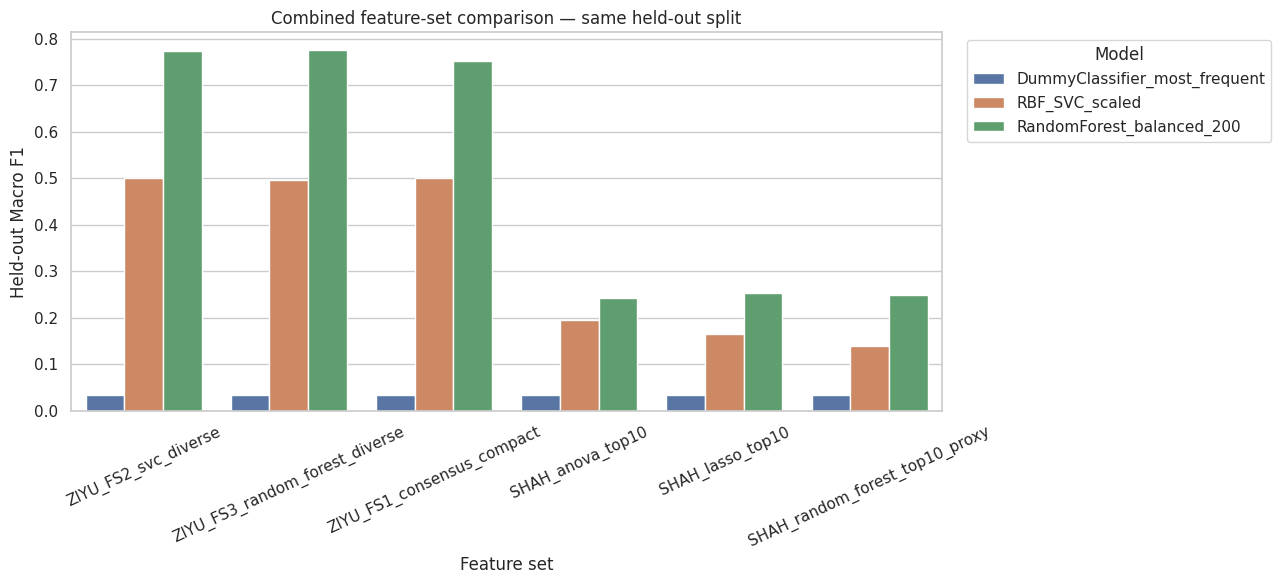

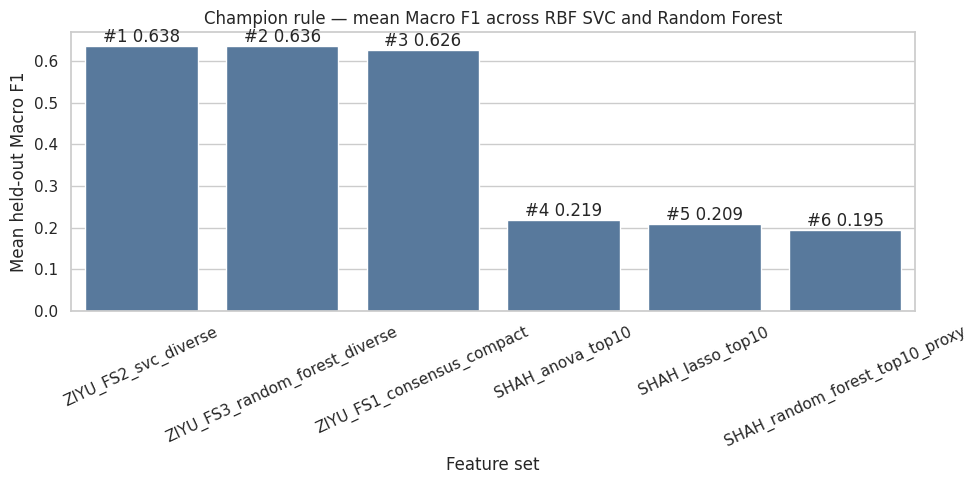

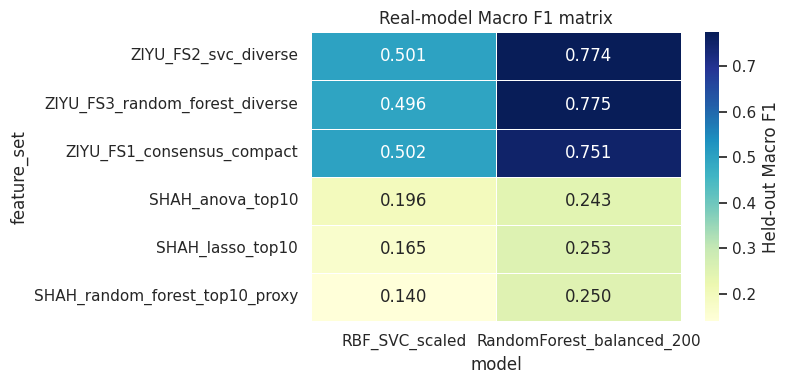

In [8]:
# Visual evidence for FigJam and the results folder.
model_order = ['DummyClassifier_most_frequent', 'RBF_SVC_scaled', 'RandomForest_balanced_200']
plot_data = metrics.copy()
order = ranking['feature_set'].tolist()
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=plot_data, x='feature_set', y='macro_f1', hue='model', order=order, hue_order=model_order, ax=ax)
ax.set_title('Combined feature-set comparison — same held-out split')
ax.set_xlabel('Feature set'); ax.set_ylabel('Held-out Macro F1')
ax.tick_params(axis='x', rotation=25)
ax.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout(); fig.savefig(fig_dir / 'combined_macro_f1_by_feature_set_and_model.png', dpi=180, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=ranking, x='feature_set', y='mean_real_model_macro_f1', order=order, color='#4C78A8', ax=ax)
ax.set_title('Champion rule — mean Macro F1 across RBF SVC and Random Forest')
ax.set_xlabel('Feature set'); ax.set_ylabel('Mean held-out Macro F1')
ax.tick_params(axis='x', rotation=25)
for index, row in ranking.iterrows():
    ax.text(index, row['mean_real_model_macro_f1'], f"#{int(row['rank'])} {row['mean_real_model_macro_f1']:.3f}", ha='center', va='bottom')
fig.tight_layout(); fig.savefig(fig_dir / 'combined_feature_set_champion_ranking.png', dpi=180, bbox_inches='tight'); plt.show()

heatmap = real.pivot(index='feature_set', columns='model', values='macro_f1').reindex(order)
fig, ax = plt.subplots(figsize=(8, max(4, len(order) * 0.65)))
sns.heatmap(heatmap, annot=True, fmt='.3f', cmap='YlGnBu', linewidths=.5, ax=ax, cbar_kws={'label': 'Held-out Macro F1'})
ax.set_title('Real-model Macro F1 matrix')
fig.tight_layout(); fig.savefig(fig_dir / 'combined_real_model_macro_f1_heatmap.png', dpi=180, bbox_inches='tight'); plt.show()

In [9]:
# Save auditable aggregate outputs. Raw CSV data is never written to GitHub.
manifest = {
    'notebook_stage': 'V3.5 combined feature-set champion evaluation',
    'data_contract': {'raw_data_dir': str(raw_dir), 'file_pattern': FILE_PATTERN, 'cohort_rows': int(len(cohort)), 'label_count': int(cohort.label.nunique()), 'cohort_fingerprint': fingerprint},
    'split_contract': {'test_size': TEST_SIZE, 'random_state': RANDOM_STATE, 'train_rows': int(len(train_ids)), 'test_rows': int(len(test_ids)), 'split_fingerprint': split_fingerprint},
    'models': {'DummyClassifier_most_frequent': 'DummyClassifier(strategy=most_frequent)', 'RBF_SVC_scaled': 'StandardScaler + SVC(rbf, C=1.0, gamma=scale, class_weight=balanced)', 'RandomForest_balanced_200': 'RandomForestClassifier(n_estimators=200, class_weight=balanced, random_state=42)'},
    'primary_metric': 'macro_f1',
    'feature_sets': feature_sets,
    'feature_set_provenance': FEATURE_SET_PROVENANCE,
    'champion_rule': 'highest mean Macro F1 across RBF SVC and Random Forest; then highest minimum; then fewer features; then name',
    'comparison_scope': comparison_scope,
    'complete_combined_comparison': combined_comparison_complete,
    'omitted_shah_feature_sets': empty_shah_sets,
    'provisional_champion_among_evaluated_sets': champion_name,
    'provisional_champion_features': champion_features,
    'limitations': ['One fixed held-out split only', 'No group/session-aware split', 'Shah exported set membership must be recorded from his executed Colab', 'This is not deployment or fraud-detection validation']
}
metrics.to_csv(out_dir / 'combined_feature_set_metrics.csv', index=False)
ranking.to_csv(out_dir / 'combined_feature_set_ranking.csv', index=False)
with open(out_dir / 'combined_feature_set_manifest.json', 'w', encoding='utf-8') as handle:
    json.dump(manifest, handle, indent=2)
with open(out_dir / 'provisional_champion_feature_set.json', 'w', encoding='utf-8') as handle:
    json.dump({'feature_set': champion_name, 'features': champion_features, 'ranking_row': ranking.iloc[0].to_dict()}, handle, indent=2)

status = 'complete combined comparison' if combined_comparison_complete else 'PARTIAL comparison — Shah lists are absent; this is not a cross-developer champion'
summary = f'''# V3.5 Combined Feature-Set Champion

**Comparison status:** {status}

**Current best among evaluated sets:** `{champion_name}`

**Features:** `{', '.join(champion_features)}`

**Decision rule:** mean Macro F1 across RBF SVC and Random Forest; ties use the higher minimum real-model Macro F1, fewer features, then name.

**Boundary:** this result uses one shared complete-case cohort and one fixed held-out split. It is a comparison on this dataset, not evidence of deployment performance or generalisation to new users/sessions.
'''
(out_dir / '05_combined_champion_report.md').write_text(summary, encoding='utf-8')
print('Saved outputs:')
for path in sorted(out_dir.rglob('*')):
    if path.is_file(): print(' -', path.relative_to(out_dir))

Saved outputs:
 - 05_combined_champion_report.md
 - combined_feature_set_manifest.json
 - combined_feature_set_metrics.csv
 - combined_feature_set_ranking.csv
 - figures/combined_feature_set_champion_ranking.png
 - figures/combined_macro_f1_by_feature_set_and_model.png
 - figures/combined_real_model_macro_f1_heatmap.png
 - provisional_champion_feature_set.json


## Interpretation rule

Report the selected set as the **provisional held-out champion** only. A small difference between sets, one reused split, and possible session/device effects mean that repeated splits, group-aware validation, and independent data are required before any stronger conclusion.